# Model counts and changing variance

The response distribution determines what a fitted mean tells us. We first model counts whose expected value depends on exposure, then fit a continuous response whose variability increases with a predictor.

These examples show how an offset changes the expected count and how a distributional GAM can model the mean and standard deviation separately.

## Create the data

The continuous response has a nonlinear mean, a group shift, and noise that increases with x. The count response uses the same inputs and an exposure variable. We split the rows into training, validation, and test sets before choosing the model settings.


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_poisson_deviance
from nampy.models import GAMRegressor, GAMLSS

rng = np.random.default_rng(21)
x = rng.uniform(0, 1, 800)
group = pd.Categorical(rng.choice(["a", "b"], size=len(x)))
shift = 0.4 * (group == "b")
scale = 0.12 + 0.2 * x
exposure = rng.uniform(0.5, 2.5, len(x))
data = pd.DataFrame({"x": x, "group": group, "log_exposure": np.log(exposure)})
data["y"] = 1 + np.sin(2*np.pi*x) + shift + scale*rng.normal(size=len(x))
data["count"] = rng.poisson(exposure * np.exp(0.1 + 0.6*np.sin(2*np.pi*x) + shift))
fit_data, test = train_test_split(data, test_size=0.2, random_state=21)
train, validation = train_test_split(fit_data, test_size=0.25, random_state=22)


## Account for exposure in count data

Twice the exposure should produce twice the expected count when the other inputs are unchanged. With a log link, we express this by adding log(exposure) as an offset with coefficient fixed at one.

$$\log\mu(x,e)=f(x)+\beta_{\mathrm{group}}+\log e.$$


The group term shifts the linear predictor by a constant. It does not give each group its own curve or estimate a partially pooled random effect.

The exposure must also be supplied for prediction. The curves below show how the expected count changes at three exposure levels; test mean Poisson deviance summarizes the count predictions.


Test mean Poisson deviance: 1.170280859893275


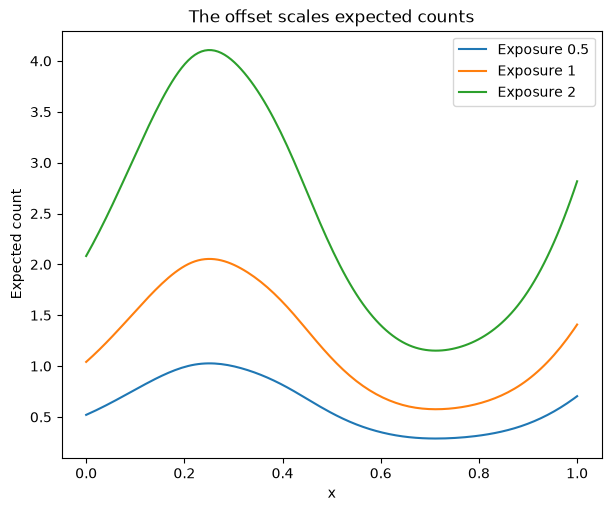

In [2]:
count_model = GAMRegressor(
    formula="count ~ s(x, bs='cr', k=10) + group + offset(log_exposure)",
    family="poisson",
).fit(train)
count_prediction = count_model.predict(test)
print("Test mean Poisson deviance:", mean_poisson_deviance(test["count"], count_prediction))

figure, axis = plt.subplots(figsize=(6, 5), constrained_layout=True)
for exposure in [0.5, 1.0, 2.0]:
    grid = pd.DataFrame({"x": np.linspace(0, 1, 150),
                         "group": pd.Categorical(["a"]*150, categories=data.group.cat.categories),
                         "log_exposure": np.log(exposure)})
    axis.plot(grid.x, count_model.predict(grid), label=f"Exposure {exposure:g}")
axis.set(xlabel="x", ylabel="Expected count", title="The offset scales expected counts")
axis.legend()
plt.show()
plt.close(figure)


## Fit a continuous-response baseline

For the continuous response, we use a Gaussian mean model using a basis dimension of 12. REML selects the smoothing strength within this basis. The fitted effect provides a baseline for examining whether the remaining spread changes with x.

In [3]:
model = GAMRegressor(formula="y ~ s(x, bs='cr', k=12) + group").fit(train)
print("Untouched test R2:", r2_score(test.y, model.predict(test)))
summary = model.summary()

Untouched test R2: 0.917785379709418

Family: gaussian
Link function: identity

Formula:
y ~ s(x, bs='cr', k=12) + group

Parametric coefficients:
                 Estimate   Std. Error      t value     Pr(>|t|)    
(Intercept)        1.0326      0.01594        64.78       <2e-16 ***
group[b]          0.36109     0.022155       16.298       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Approximate significance of smooth terms:
                      edf       Ref.df            F      p-value    
s(x)               8.8781       10.093       427.14       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-sq.(adj) = 0.906   Deviance explained = 90.8%
-REML = 19.112  Scale est. = 0.058054  n = 480


The summary reports the fitted mean relationship and its effective degrees of freedom. The following effect plot shows its shape; we examine the validation residuals below to assess what this mean-only fit leaves unexplained.

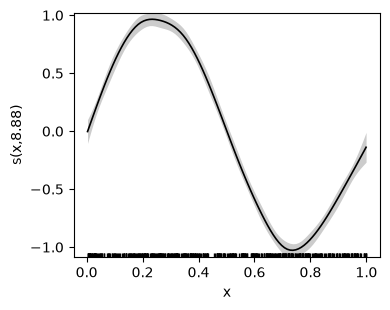

In [4]:
figures = model.plot(pages=1, scheme=1, scale=0)
plt.show()
plt.close("all")
parts = model.predict_components(test)
parts.validate_additive_reconstruction()



The curve is a centered contribution to the mean. Its band describes uncertainty in the estimated effect under the fitted model's common-scale assumption. Our simulation has increasing noise, so we will examine that assumption before interpreting the model as a description of the full response distribution.


## Check whether the spread changes

Squared residuals on the validation rows tend to increase with x. They are noisy, but the pattern suggests that a single residual scale is inadequate. We therefore fit a model in which standard deviation can vary with x as well as the mean.


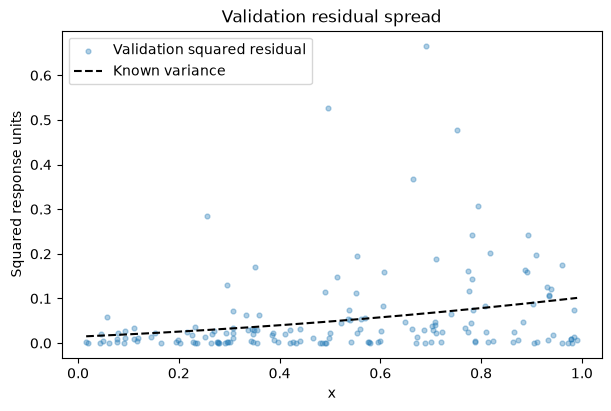

In [5]:
residual = validation.y.to_numpy() - model.predict(validation)
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
axis.scatter(validation.x, residual**2, s=12, alpha=.35, label="Validation squared residual")
axis.plot(np.sort(validation.x), (0.12 + .2*np.sort(validation.x))**2, "k--", label="Known variance")
axis.set(xlabel="x", ylabel="Squared response units", title="Validation residual spread")
axis.legend()
plt.show()
plt.close(figure)

## Model the mean and standard deviation

A normal GAMLSS estimates both parameters together. The mean formula includes a smooth of x and a group shift. The scale formula contains a smooth of x only.

For one observation, the negative log likelihood contains log(sigma) + (y-mu)^2 / (2 sigma^2), apart from a constant. This balances the residual size against the cost of predicting a large scale.


Test negative log likelihood: -0.129


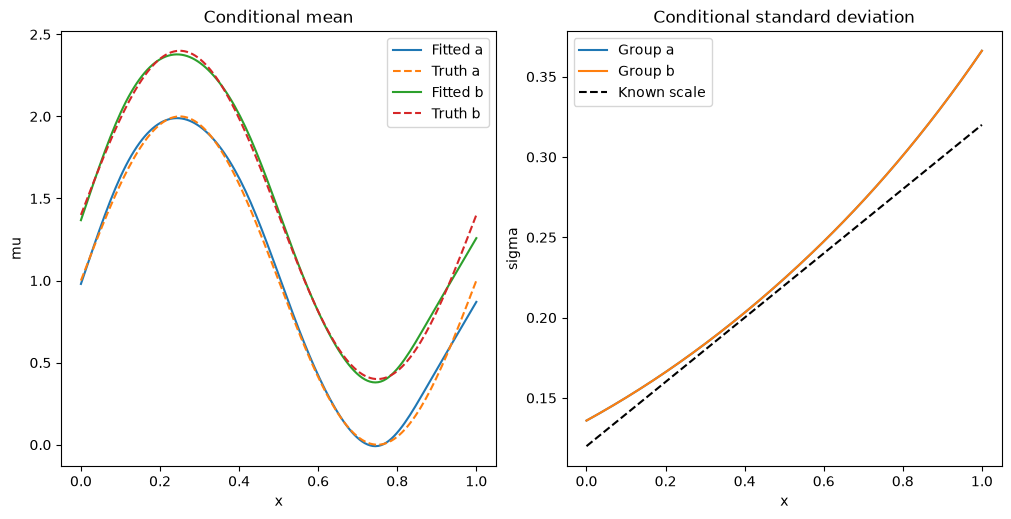

In [6]:
distributional = GAMLSS(family="normal", formula={
    "mu": "y ~ s(x, bs='cr', k=10) + group",
    "sigma": "~ s(x, bs='cr', k=8)",
}).fit(train)
parameters = distributional.predict_parameters(test)
components = distributional.predict_components(test)
components.validate_additive_reconstruction()
print("Test negative log likelihood:", round(distributional.evaluate(test, test.y.to_numpy())["Negative Log-Likelihood"], 3))

figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for group in data.group.cat.categories:
    grid = pd.DataFrame({"x": np.linspace(0, 1, 150),
                         "group": pd.Categorical([group]*150, categories=data.group.cat.categories)})
    mu, sigma = distributional.predict_parameters(grid).T
    axes[0].plot(grid.x, mu, label=f"Fitted {group}")
    axes[0].plot(grid.x, 1 + np.sin(2*np.pi*grid.x) + 0.4*(group == "b"), "--", label=f"Truth {group}")
    axes[1].plot(grid.x, sigma, label=f"Group {group}")
axes[1].plot(grid.x, 0.12 + 0.2*grid.x, "k--", label="Known scale")
axes[0].set(title="Conditional mean", xlabel="x", ylabel="mu")
axes[1].set(title="Conditional standard deviation", xlabel="x", ylabel="sigma")
for axis in axes:
    axis.set_box_aspect(1)
    axis.legend()
plt.show()
plt.close(figure)


The dashed lines show the known mean and standard deviation used to generate the data. The fitted group means differ, but the fitted scale curves coincide because the scale formula contains no group term. The scale describes variation in future responses; it is a different quantity from the uncertainty band around the earlier mean effect.

The [formula reference](../user_guide/formula_visual_reference.rst) shows other group and smooth structures.
